
# **Контрольная** **работа** **№** **1**
## Классификация изображений грибов с использованием свёрточных нейронных сетей

**Выполнил:** Билетин Максим

**Группа:** 24.Б02-ПУ

**Кафедра:** Теории Программирования (ТП)

---

### Цель работы

Разработать и обучить модель свёрточной нейронной сети для классификации изображений грибов по родам с использованием метода переноса обучения (Transfer Learning).

### Задачи работы

1. Исследовать структуру набора данных Mushrooms Classification.
2. Подготовить изображения для обучения нейронной сети.
3. Реализовать классификатор на основе предобученной ResNet18.
4. Провести обучение и оценить изменение функции потерь.
5. Рассчитать точность классификации на обучающей и тестовой выборках.
6. Построить графики обучения и матрицу ошибок.
7. Проанализировать полученные результаты и сформулировать выводы.

### Исходный набор данных

[Mushrooms Classification — Common Genus's Images](https://www.kaggle.com/datasets/maysee/mushrooms-classification-common-genuss-images)


## 1. Подготовка вычислительной среды

### 1.1. Программное окружение

В работе используется язык программирования Python и библиотека PyTorch для реализации и обучения нейронной сети.

Вычисления выполняются в среде Google Colab с возможностью аппаратного ускорения на GPU.

Для воспроизводимости эксперимента фиксируется начальное состояние генераторов случайных чисел.

Для загрузки набора изображений применяется библиотека KaggleHub.


In [ ]:

%pip install -q kagglehub

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision
import kagglehub

from pathlib import Path
from PIL import Image
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4



## 2. Загрузка и исследование набора данных

### 2.1. Описание датасета

Для решения задачи используется набор фотографий грибов Mushrooms Classification — Common Genus's Images, опубликованный на платформе Kaggle.

Целевой переменной является принадлежность изображения к определённому роду грибов.

В отличие от задачи бинарной классификации, в данном случае рассматривается многоклассовая классификация изображений.

Перед обучением необходимо исследовать структуру датасета, определить количество классов, численность изображений и распределение наблюдений между категориями.

Для последующей загрузки изображений планируется использовать `torchvision.datasets.ImageFolder`.


In [ ]:

DATASET_ID = (
    "maysee/mushrooms-classification-common-genuss-images"
)

dataset_path = kagglehub.dataset_download(DATASET_ID)

DATA_DIR = Path(dataset_path)

print("Датасет загружен")
print("Расположение:", DATA_DIR)


100%|██████████| 1.85G/1.85G [00:16<00:00, 118MB/s]

Extracting files...


Датасет загружен
Расположение: /root/.cache/kagglehub/datasets/maysee/mushrooms-classification-common-genuss-images/versions/1


In [ ]:

assert DATA_DIR.exists(), "Папка датасета не найдена"

print("Содержимое корневой директории:\n")

for item in sorted(DATA_DIR.iterdir()):
    print(
        "📁" if item.is_dir() else "📄",
        item.name
    )

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_paths = [
    path for path in DATA_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
]

print("\nКоличество найденных изображений:",
      len(image_paths))

print("\nПримеры путей:")
for path in image_paths[:5]:
    print(path.relative_to(DATA_DIR))


Содержимое корневой директории:

📁 Mushrooms
📁 mushrooms

Количество найденных изображений: 13428

Примеры путей:
mushrooms/Mushrooms/Amanita/007_d382tiPX4lI.jpg
mushrooms/Mushrooms/Amanita/447_YuqrlLRUFco.jpg
mushrooms/Mushrooms/Amanita/321_x3NSjQopjwI.jpg
mushrooms/Mushrooms/Amanita/766_iDERt11pzvQ.jpg
mushrooms/Mushrooms/Amanita/493_yOZ_HrxrQNI.jpg



### 2.2. Первичный анализ структуры датасета

После загрузки исходного набора данных обнаружено 13 428 файлов изображений.

В корневой директории расположены два каталога: `Mushrooms` и `mushrooms`.

Для корректной подготовки данных необходимо установить фактическую структуру категорий, определить количество изображений для каждого рода грибов и проверить возможное дублирование данных.

Полученные сведения будут использованы при формировании обучающей, валидационной и тестовой выборок.


In [ ]:

from collections import Counter

folder_counts = Counter(
    str(path.parent.relative_to(DATA_DIR))
    for path in image_paths
)

print("Количество папок с изображениями:",
      len(folder_counts))

print("\nРаспределение изображений:\n")

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

print("\nВсего изображений:",
      sum(folder_counts.values()))


Количество папок с изображениями: 18

Распределение изображений:

Mushrooms/Agaricus: 353
Mushrooms/Amanita: 750
Mushrooms/Boletus: 1073
Mushrooms/Cortinarius: 836
Mushrooms/Entoloma: 364
Mushrooms/Hygrocybe: 316
Mushrooms/Lactarius: 1563
Mushrooms/Russula: 1148
Mushrooms/Suillus: 311
mushrooms/Mushrooms/Agaricus: 353
mushrooms/Mushrooms/Amanita: 750
mushrooms/Mushrooms/Boletus: 1073
mushrooms/Mushrooms/Cortinarius: 836
mushrooms/Mushrooms/Entoloma: 364
mushrooms/Mushrooms/Hygrocybe: 316
mushrooms/Mushrooms/Lactarius: 1563
mushrooms/Mushrooms/Russula: 1148
mushrooms/Mushrooms/Suillus: 311

Всего изображений: 13428



### 2.3. Анализ структуры и повторяемости данных

В результате первичного исследования обнаружено 13 428 файлов изображений, расположенных в 18 каталогах.

Анализ структуры показал, что датасет содержит 9 родов грибов, каждый из которых представлен в двух каталогах с одинаковым числом изображений.

Общее количество изображений в одной структуре каталогов составляет 6 714.

Для исключения возможного дублирования данных проводится проверка совпадения содержимого файлов.

Это необходимо для предотвращения утечки данных (Data Leakage) при последующем формировании обучающей и тестовой выборок.


In [ ]:

import filecmp

root_a = DATA_DIR / "Mushrooms"
root_b = DATA_DIR / "mushrooms" / "Mushrooms"

def get_files(root):
    return {
        p.relative_to(root): p
        for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    }

files_a = get_files(root_a)
files_b = get_files(root_b)

common = set(files_a) & set(files_b)

identical = sum(
    filecmp.cmp(
        files_a[name],
        files_b[name],
        shallow=False
    )
    for name in common
)

print("Каталог A:", len(files_a))
print("Каталог B:", len(files_b))
print("Общие пути:", len(common))
print("Идентичные файлы:", identical)

if (
    len(files_a) == len(files_b) == len(common)
    and identical == len(common)
):
    DATASET_ROOT = root_a
    print("\nКаталоги идентичны.")
    print("Используем:", DATASET_ROOT)
else:
    raise ValueError(
        "Каталоги различаются. "
        "Нужно дополнительно исследовать данные."
    )


Каталог A: 6714
Каталог B: 6714
Общие пути: 6714
Идентичные файлы: 6714

Каталоги идентичны.
Используем: /root/.cache/kagglehub/datasets/maysee/mushrooms-classification-common-genuss-images/versions/1/Mushrooms



### 2.4. Результаты проверки дублирования данных

Проверка двух каталогов с использованием побайтового сравнения файлов показала их полную идентичность.

В каждом каталоге находится 6 714 изображений, причём все файлы с одинаковыми относительными путями имеют идентичное содержимое.

Таким образом, исходные 13 428 файлов включают две копии одного набора изображений.

Для дальнейшего анализа выбран один каталог `Mushrooms`, содержащий фотографии девяти родов грибов.

Исключение второй копии позволяет избежать искусственного увеличения выборки и предотвращает попадание этих копий в разные подвыборки.


In [ ]:

from torchvision import datasets
from collections import Counter

mushroom_dataset = datasets.ImageFolder(
    root=DATASET_ROOT
)

class_names = mushroom_dataset.classes

num_classes = len(class_names)

class_counts = Counter(mushroom_dataset.targets)

class_distribution = pd.DataFrame({
    "Genus": class_names,
    "Images": [
        class_counts[i] for i in range(num_classes)
    ]
})

print("Всего изображений:", len(mushroom_dataset))
print("Количество классов:", num_classes)
print("\nНазвания классов:")
print(class_names)

display(class_distribution)


Всего изображений: 6714
Количество классов: 9

Названия классов:
['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


,Genus,Images
0,Agaricus,353
1,Amanita,750
2,Boletus,1073
3,Cortinarius,836
4,Entoloma,364
5,Hygrocybe,316
6,Lactarius,1563
7,Russula,1148
8,Suillus,311



### 2.5. Распределение изображений по классам

Для исследования структуры набора данных использован класс `ImageFolder` библиотеки Torchvision.

Названия подкаталогов автоматически определяют метки классов, а соответствующим изображениям присваиваются числовые идентификаторы.

Анализ распределения изображений позволяет определить численность каждого рода грибов и оценить сбалансированность выборки.

Неравномерность количества фотографий в разных классах может влиять на процесс обучения и качество распознавания редко представленных родов.


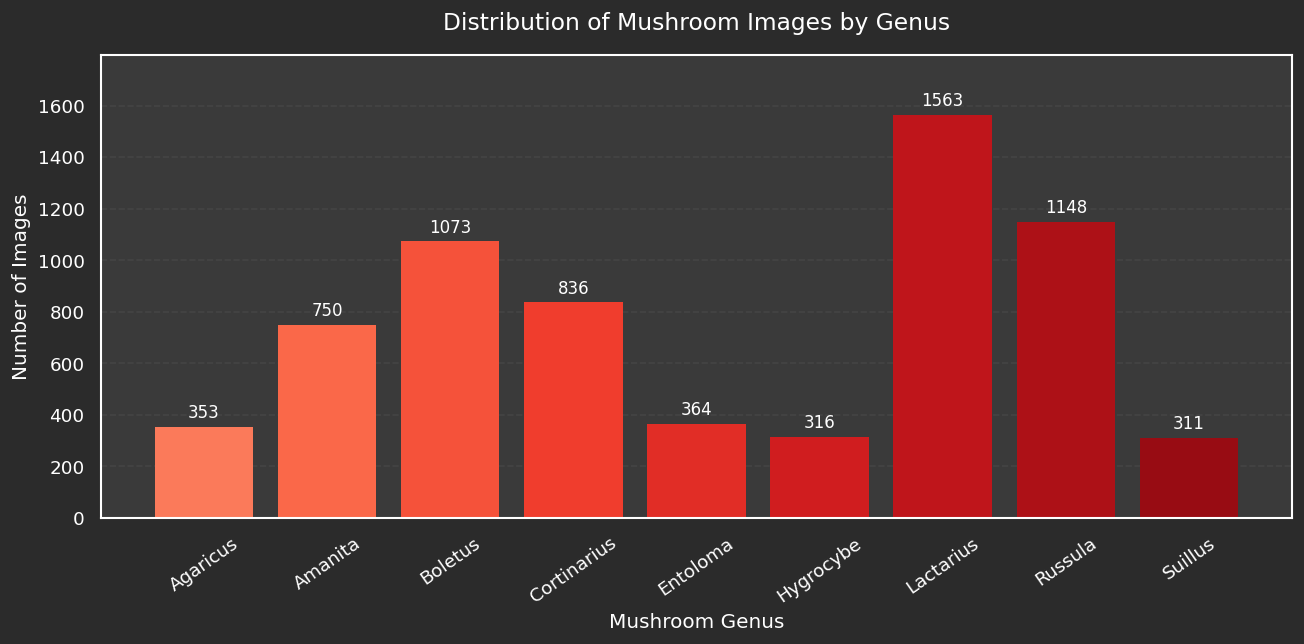

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

genus = class_distribution["Genus"]
images = class_distribution["Images"]

colors = plt.cm.Reds(np.linspace(0.45, 0.9, len(genus)))

fig, ax = plt.subplots(figsize=(11, 5.5))

fig.patch.set_facecolor("#2b2b2b")
ax.set_facecolor("#3a3a3a")

bars = ax.bar(genus, images, color=colors, edgecolor="none", linewidth=1)

ax.set_title(
    "Distribution of Mushroom Images by Genus",
    color="white",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Mushroom Genus", color="white")
ax.set_ylabel("Number of Images", color="white")

ax.tick_params(axis="x", colors="white", rotation=35)
ax.tick_params(axis="y", colors="white")

for spine in ax.spines.values():
    spine.set_color("white")

ax.grid(axis="y", color="grey", alpha=0.15, linestyle="--")

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 20,
        f"{int(height)}",
        ha="center",
        va="bottom",
        color="white",
        fontsize=10
    )

ax.set_ylim(0, max(images) * 1.15)

ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()



### 2.6. Анализ распределения изображений по родам грибов

В результате анализа установлено, что исследуемый набор данных содержит **6 714 изображений**, распределённых между девятью родами грибов.

Наибольшее количество фотографий относится к роду `Lactarius` — 1563 изображения. Также широко представлены роды `Russula` (1148 изображений) и `Boletus` (1073 изображения).

Наименее многочисленными являются классы `Suillus` (311 изображений), `Hygrocybe` (316 изображений) и `Agaricus` (353 изображения).

Отношение численности наиболее представленного класса к наименее представленному составляет:

$$
K = \frac{N_{\max}}{N_{\min}}
= \frac{1563}{311} \approx 5.03.
$$

Таким образом, исходный набор данных характеризуется заметным дисбалансом классов.

Неравномерность распределения может приводить к смещению классификационной модели в сторону наиболее многочисленных категорий.

**Вывод:** при обучении и оценке нейронной сети необходимо учитывать дисбаланс классов. Помимо общей точности классификации (Accuracy), целесообразно использовать метрики Precision, Recall и Macro F1-score.



### 2.7. Визуальный анализ изображений грибов

Для предварительного изучения визуальных характеристик объектов выполнена выборочная визуализация фотографий из каждого класса.

Изображения представлены в виде сетки 3 × 3, содержащей по одному случайно выбранному примеру каждого рода грибов.

Цель визуализации — оценить разнообразие внешних признаков грибов, особенности освещения, фона, ракурса и масштаба изображений.

Полученные наблюдения используются при выборе методов предобработки изображений и архитектуры нейронной сети.


In [ ]:

rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(3, 3, figsize=(11, 11))

fig.patch.set_facecolor("#2b2b2b")

for class_idx, ax in enumerate(axes.flat):

    indices = np.where(
        np.array(mushroom_dataset.targets) == class_idx
    )[0]

    idx = int(rng.choice(indices))

    image, label = mushroom_dataset[idx]

    ax.imshow(image)

    ax.set_title(
        class_names[label],
        color="white",
        fontsize=13,
        fontweight="medium",
        pad=10
    )

    ax.axis("off")

plt.suptitle(
    "Examples of Mushroom Genera",
    fontsize=17,
    color="white",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


Output hidden; open in https://colab.research.google.com to view.


### 2.8. Анализ визуальных характеристик изображений

В ходе визуального исследования рассмотрены фотографии девяти родов грибов, представленных в исходном наборе данных.

Установлено, что изображения характеризуются значительным разнообразием внешних признаков объектов, включая форму и окраску шляпки, строение ножки и особенности гименофора.

Фотографии получены при различных условиях освещения, ракурсах и масштабах. На отдельных изображениях присутствует несколько плодовых тел, а также неоднородный природный фон.

Указанные особенности повышают сложность задачи классификации, поскольку нейронной сети необходимо выделять информативные признаки грибов при изменении условий съёмки.

**Вывод:** для решения поставленной задачи целесообразно использовать свёрточную нейронную сеть ResNet18 с предварительно обученными весами и аугментацией изображений обучающей выборки.



## 3. Подготовка данных для обучения

### 3.1. Проверка дублирования изображений

Перед формированием обучающей, валидационной и тестовой выборок проводится проверка повторяющихся файлов изображений.

Для каждого файла рассчитывается криптографическая хеш-сумма SHA-256, позволяющая выявлять файлы с идентичным содержимым.

Проверка необходима для исключения попадания одинаковых изображений в разные выборки, что могло бы привести к утечке данных (Data Leakage) и завышению оценки качества классификации.


In [ ]:

import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for idx, (path, label) in enumerate(mushroom_dataset.samples):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            sha256.update(chunk)

    file_hash = sha256.hexdigest()
    hash_groups[file_hash].append(idx)

duplicate_groups = {
    h: indices
    for h, indices in hash_groups.items()
    if len(indices) > 1
}

extra_copies = sum(
    len(indices) - 1
    for indices in duplicate_groups.values()
)

conflicting_groups = [
    indices
    for indices in duplicate_groups.values()
    if len({
        mushroom_dataset.targets[i]
        for i in indices
    }) > 1
]

print("Всего изображений:", len(mushroom_dataset))
print("Уникальных файлов:", len(hash_groups))
print("Групп дубликатов:", len(duplicate_groups))
print("Лишних копий:", extra_copies)
print("Дубликатов между классами:",
      len(conflicting_groups))


Всего изображений: 6714
Уникальных файлов: 6645
Групп дубликатов: 69
Лишних копий: 69
Дубликатов между классами: 0



### 3.2. Результаты проверки дублирования

В результате расчёта хеш-сумм SHA-256 для 6714 изображений выявлено 6645 уникальных файлов.

Обнаружено 69 групп дубликатов, содержащих 69 избыточных копий изображений.

Совпадений файлов между различными классами не установлено.

Доля избыточных копий составляет:

$$
D=\frac{69}{6714}\cdot100\%\approx1.03\%.
$$

Для дальнейшей обработки используются только уникальные файлы. Повторные экземпляры исключаются из выборки без физического удаления исходных изображений.

Такой подход позволяет предотвратить попадание точных копий одного изображения одновременно в обучающую и тестовую выборки.

Проверка основана на совпадении содержимого файлов и не исключает наличия визуально похожих фотографий, сохранённых в разных форматах или с различным сжатием.



### 3.3. Формирование обучающей, валидационной и тестовой выборок

Для обучения и оценки нейронной сети исходный набор уникальных изображений разделяется на три независимые подвыборки:

- **Train (70%)** — используется для оптимизации параметров модели.
- **Validation (15%)** — применяется для контроля процесса обучения и выбора гиперпараметров.
- **Test (15%)** — предназначена для окончательной оценки качества классификации.

Разделение выполняется методом стратифицированной случайной выборки с использованием функции `train_test_split` библиотеки Scikit-learn.

Стратификация обеспечивает приблизительное сохранение исходных пропорций классов.

Для воспроизводимости результатов используется фиксированное значение `random_state = 42`.

Повторяющиеся файлы исключаются до разделения данных, что предотвращает попадание точных копий изображений в разные выборки.


In [ ]:

from sklearn.model_selection import train_test_split

unique_indices = np.array([
    indices[0]
    for indices in hash_groups.values()
])

unique_labels = np.array([
    mushroom_dataset.targets[i]
    for i in unique_indices
])

assert len(unique_indices) == 6645

train_indices, remaining_indices = train_test_split(
    unique_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=unique_labels
)

remaining_labels = np.array([
    mushroom_dataset.targets[i]
    for i in remaining_indices
])

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_labels
)

train_set = set(train_indices)
val_set = set(val_indices)
test_set = set(test_indices)

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

assert (
    len(train_set | val_set | test_set)
    == len(unique_indices)
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

print("\nВсего:",
      len(train_indices)
      + len(val_indices)
      + len(test_indices))

print("\nПересечений между выборками нет.")


Train: 4651
Validation: 997
Test: 997

Всего: 6645

Пересечений между выборками нет.



### 3.4. Предобработка изображений для ResNet18

Для классификации изображений используется свёрточная нейронная сеть ResNet18, предварительно обученная на наборе данных ImageNet.

Входные изображения преобразуются к размеру 224 × 224 пикселя и представляются в формате RGB с тремя цветовыми каналами.

Нормализация выполняется по формуле:

$$
x'_{c}=\frac{x_c-\mu_c}{\sigma_c},
$$

где $x_c$ — значение пикселя соответствующего цветового канала, $\mu_c$ — среднее значение, $\sigma_c$ — стандартное отклонение.

Используются параметры нормализации ImageNet:

$$
\mu=(0.485,\ 0.456,\ 0.406),
$$

$$
\sigma=(0.229,\ 0.224,\ 0.225).
$$

Для обучающей выборки применяется аугментация изображений, включающая случайное кадрирование, горизонтальное отражение и небольшие повороты.

Для валидационной и тестовой выборок используются детерминированные преобразования, соответствующие предобученным весам ResNet18.

Аугментация применяется только к обучающим изображениям и предназначена для повышения устойчивости модели к изменениям ракурса и положения объектов.


In [ ]:

from torchvision import transforms, models
from torch.utils.data import Dataset
from PIL import Image

weights = models.ResNet18_Weights.DEFAULT

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.75, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = weights.transforms()

class MushroomSubset(Dataset):

    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        original_idx = int(self.indices[idx])

        path, label = self.base_dataset.samples[original_idx]

        with Image.open(path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image, label

train_dataset = MushroomSubset(
    mushroom_dataset, train_indices, train_transform
)

val_dataset = MushroomSubset(
    mushroom_dataset, val_indices, eval_transform
)

test_dataset = MushroomSubset(
    mushroom_dataset, test_indices, eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Transforms configured successfully")


Train: 4651
Validation: 997
Test: 997
Transforms configured successfully


In [ ]:

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Number of classes:", num_classes)

assert images.shape[1:] == (3, 224, 224)
assert labels.min() >= 0
assert labels.max() < num_classes

print("DataLoader verification successful")


Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Number of classes: 9
DataLoader verification successful


### 3.5. Контроль целостности изображений

Перед обучением нейронной сети проведена проверка целостности 6645 уникальных файлов изображений с использованием библиотеки Pillow.

В результате обнаружен один повреждённый файл, относящийся к классу `Russula`. При его декодировании возникала ошибка неполноты данных изображения.

Повреждённый файл исключён из обучающей выборки без удаления исходного файла с диска.

После фильтрации итоговый набор данных составил 6644 изображения, распределённых следующим образом:

| Выборка | Количество изображений |
|---|---:|
| Train | 4650 |
| Validation | 997 |
| Test | 997 |
| **Всего** | **6644** |

Для продолжения эксперимента объекты Dataset и DataLoader были пересозданы, а классификационный слой ResNet18 и оптимизатор Adam повторно инициализированы.

Таким образом, обеспечена корректная обработка изображений при обучении нейронной сети.

In [ ]:

from PIL import Image, ImageFile
from torch.utils.data import DataLoader
import numpy as np

ImageFile.LOAD_TRUNCATED_IMAGES = False

bad_indices = set()

for idx in unique_indices:
    idx = int(idx)
    path, label = mushroom_dataset.samples[idx]

    try:
        with Image.open(path) as img:
            img.convert("RGB").load()

    except Exception as error:
        bad_indices.add(idx)
        print(f"Повреждённый файл: {path}")
        print(f"Причина: {error}\n")

print("Проверено изображений:", len(unique_indices))
print("Повреждённых изображений:", len(bad_indices))

def remove_bad_indices(indices):
    return np.array([
        int(i) for i in indices
        if int(i) not in bad_indices
    ], dtype=int)

train_indices = remove_bad_indices(train_indices)
val_indices = remove_bad_indices(val_indices)
test_indices = remove_bad_indices(test_indices)

train_dataset = MushroomSubset(
    mushroom_dataset, train_indices, train_transform
)

val_dataset = MushroomSubset(
    mushroom_dataset, val_indices, eval_transform
)

test_dataset = MushroomSubset(
    mushroom_dataset, test_indices, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nОбновлённые выборки:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Всего:", (
    len(train_dataset)
    + len(val_dataset)
    + len(test_dataset)
))

print("\nПодготовка данных завершена.")


Повреждённый файл: /root/.cache/kagglehub/datasets/maysee/mushrooms-classification-common-genuss-images/versions/1/Mushrooms/Russula/092_43B354vYxm8.jpg
Причина: image file is truncated (92 bytes not processed)

Проверено изображений: 6645
Повреждённых изображений: 1

Обновлённые выборки:
Train: 4650
Validation: 997
Test: 997
Всего: 6644

Подготовка данных завершена.



## 4. Разработка нейросетевой модели

### 4.1. Архитектура ResNet18

Для решения задачи классификации изображений грибов выбрана свёрточная нейронная сеть ResNet18, предварительно обученная на наборе данных ImageNet.

ResNet18 представляет собой остаточную нейронную сеть, содержащую 18 слоёв с обучаемыми параметрами.

Основной особенностью архитектуры являются остаточные соединения (Residual Connections), позволяющие передавать информацию между блоками сети.

Математически остаточный блок описывается выражением:

$$
\mathbf{y}=F(\mathbf{x},W)+\mathbf{x},
$$

где:

- $\mathbf{x}$ — входной тензор;
- $F(\mathbf{x},W)$ — преобразование, реализуемое свёрточными слоями;
- $W$ — обучаемые параметры;
- $\mathbf{y}$ — выход остаточного блока.

Остаточные соединения облегчают оптимизацию глубоких нейронных сетей.

### 4.2. Метод Transfer Learning

В работе применяется перенос обучения (Transfer Learning).

Предварительно обученная ResNet18 используется для извлечения визуальных признаков изображений. Параметры свёрточных слоёв на первоначальном этапе фиксируются.

Исходный классификационный слой, рассчитанный на 1000 категорий ImageNet, заменяется новым полносвязным слоем с девятью выходами, соответствующими исследуемым родам грибов.

Таким образом, архитектура классификатора имеет вид:

$$
512\rightarrow9.
$$

На первом этапе обучения оптимизируются только параметры нового классификационного слоя.

Это позволяет использовать признаки, изученные нейронной сетью на большом наборе изображений, и адаптировать модель к поставленной задаче.


In [ ]:

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features

model.fc = nn.Linear(
    in_features=num_features,
    out_features=num_classes
)

model = model.to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Architecture: ResNet18")
print("Device:", device)
print("Input features:", num_features)
print("Output classes:", num_classes)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("\nClassifier:")
print(model.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


Architecture: ResNet18
Device: cuda
Input features: 512
Output classes: 9
Total parameters: 11,181,129
Trainable parameters: 4,617

Classifier:
Linear(in_features=512, out_features=9, bias=True)


In [ ]:

model.eval()

images, labels = next(iter(train_loader))

sample_images = images[:2].to(device)

with torch.inference_mode():
    outputs = model(sample_images)

print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(outputs.shape))

assert outputs.shape == (2, num_classes)

print("ResNet18 forward pass successful")


Input shape: (2, 3, 224, 224)
Output shape: (2, 9)
ResNet18 forward pass successful



## 5. Обучение нейронной сети

### 5.1. Настройка процесса обучения

Для оптимизации параметров классификационного слоя ResNet18 используется алгоритм Adam.

В качестве функции потерь применяется категориальная перекрёстная энтропия (Cross-Entropy Loss):

$$
L=-\frac{1}{N}\sum_{i=1}^{N}
\log p_{i,y_i},
$$

где:

- $N$ — количество объектов в выборке;
- $p_{i,y_i}$ — предсказанная вероятность истинного класса объекта $i$.

Точность классификации рассчитывается как:

$$
Accuracy=\frac{N_{\mathrm{correct}}}{N_{\mathrm{total}}}\cdot100\%.
$$

На первом этапе обучения параметры свёрточной части сети фиксируются, а оптимизации подвергается только последний полносвязный слой.

Используются следующие гиперпараметры:

| Гиперпараметр | Значение |
|---|---|
| Оптимизатор | Adam |
| Learning Rate | 0.001 |
| Weight Decay | 0.0001 |
| Batch Size | 32 |
| Максимальное число эпох | 12 |
| Функция потерь | CrossEntropyLoss |
| Критерий выбора модели | Минимальный Validation Loss |

Для контроля переобучения применяется механизм Early Stopping.

Если валидационная ошибка не уменьшается на протяжении четырёх последовательных эпох, обучение прекращается досрочно.

Для последующего тестирования сохраняются параметры модели, соответствующие минимальной валидационной ошибке.


In [ ]:

import copy
import time

EPOCHS = 12
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
PATIENCE = 4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None

    model.eval()

    if is_training:
        model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(
            device, non_blocking=True
        )
        labels = labels.to(
            device, non_blocking=True
        )

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        correct += (predictions == labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

print("Training functions initialized")


Training functions initialized


In [ ]:

model.fc.reset_parameters()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Классификатор и оптимизатор переинициализированы.")


Классификатор и оптимизатор переинициализированы.


In [ ]:

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
best_weights = None
epochs_without_improvement = 0

checkpoint_path = "/content/mushrooms_resnet18_best.pth"

print("Starting ResNet18 training...\n")

for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        optimizer
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {val_acc:.2%}"
    )

    if val_loss < best_val_loss - 1e-4:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(
            model.state_dict()
        )

        torch.save({
            "model_state_dict": best_weights,
            "class_names": class_names,
            "num_classes": num_classes,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss
        }, checkpoint_path)

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping activated")
        break

model.load_state_dict(best_weights)
model.eval()

print("\nTraining completed")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", checkpoint_path)


Starting ResNet18 training...



Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b6997222de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b6997222de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 01/12 | Train Loss: 1.5043 | Val Loss: 1.1298 | Train Acc: 49.33% | Val Acc: 63.79%
Epoch 02/12 | Train Loss: 1.0629 | Val Loss: 0.9771 | Train Acc: 64.43% | Val Acc: 66.50%
Epoch 03/12 | Train Loss: 0.9339 | Val Loss: 0.8837 | Train Acc: 68.32% | Val Acc: 69.11%
Epoch 04/12 | Train Loss: 0.8695 | Val Loss: 0.8457 | Train Acc: 70.56% | Val Acc: 70.51%
Epoch 05/12 | Train Loss: 0.8194 | Val Loss: 0.8341 | Train Acc: 71.96% | Val Acc: 68.91%
Epoch 06/12 | Train Loss: 0.7932 | Val Loss: 0.8412 | Train Acc: 73.18% | Val Acc: 72.02%
Epoch 07/12 | Train Loss: 0.7612 | Val Loss: 0.7844 | Train Acc: 73.66% | Val Acc: 71.92%
Epoch 08/12 | Train Loss: 0.7453 | Val Loss: 0.8367 | Train Acc: 74.28% | Val Acc: 70.81%
Epoch 09/12 | Train Loss: 0.7239 | Val Loss: 0.8026 | Train Acc: 75.18% | Val Acc: 72.62%
Epoch 10/12 | Train Loss: 0.6944 | Val Loss: 0.8174 | Train Acc: 75.94% | Val Acc: 71.01%
Epoch 11/12 | Train Loss: 0.7003 | Val Loss: 0.7650 | Train Acc: 76.17% | Val Acc: 74.12%
Epoch 12/1

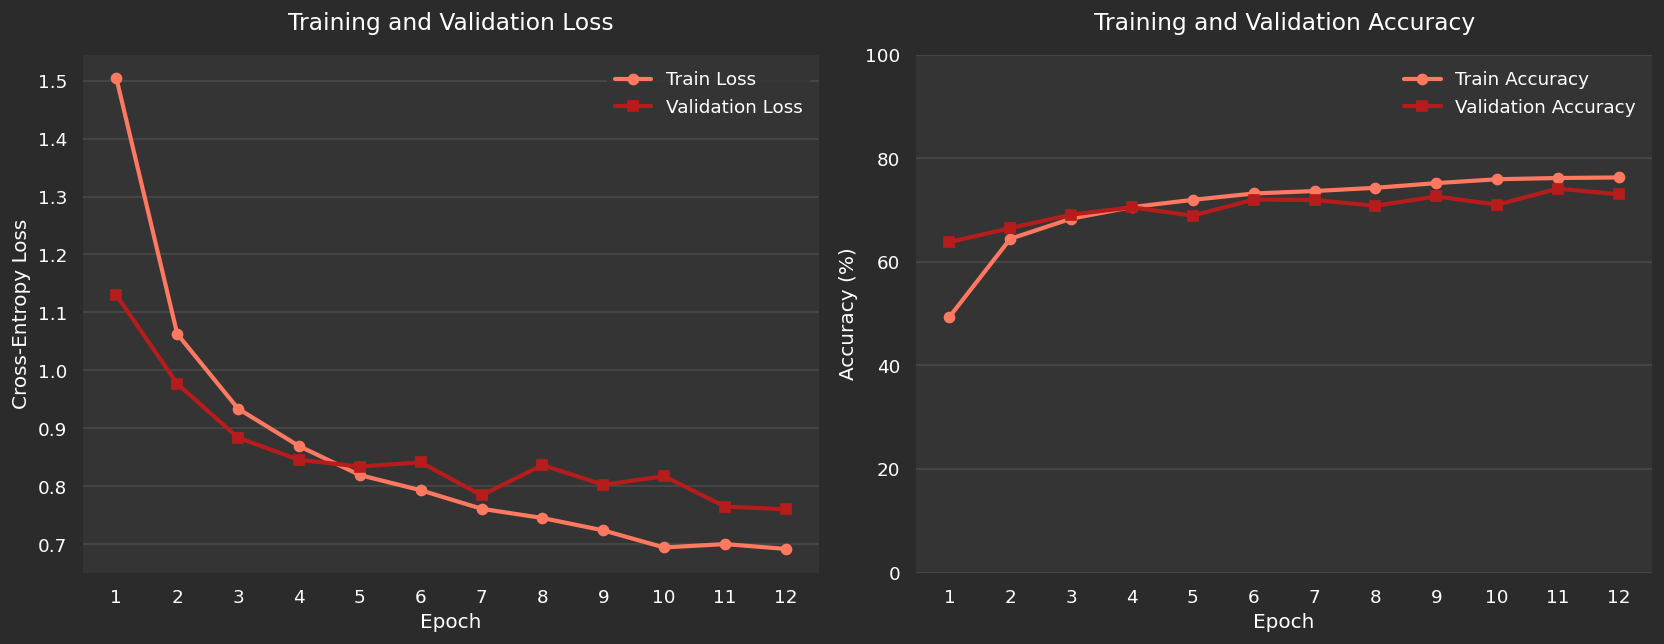

In [ ]:

epochs = np.arange(
    1, len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5)
)

fig.patch.set_facecolor("#2b2b2b")

for ax in axes:
    ax.set_facecolor("#343434")
    ax.grid(axis="y", color="white", alpha=0.10)
    ax.grid(axis="x", visible=False)

    ax.tick_params(colors="white")

    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(
    epochs,
    history["train_loss"],
    color="#ff7961",
    linewidth=2.5,
    marker="o",
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history["val_loss"],
    color="#b71c1c",
    linewidth=2.5,
    marker="s",
    label="Validation Loss"
)

axes[0].set_title(
    "Training and Validation Loss",
    color="white",
    pad=15
)

axes[0].set_xlabel("Epoch", color="white")
axes[0].set_ylabel("Cross-Entropy Loss", color="white")

axes[1].plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    color="#ff7961",
    linewidth=2.5,
    marker="o",
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    color="#b71c1c",
    linewidth=2.5,
    marker="s",
    label="Validation Accuracy"
)

axes[1].set_title(
    "Training and Validation Accuracy",
    color="white",
    pad=15
)

axes[1].set_xlabel("Epoch", color="white")
axes[1].set_ylabel("Accuracy (%)", color="white")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xticks(epochs)
    legend = ax.legend(
        facecolor="#343434",
        edgecolor="none"
    )
    for text in legend.get_texts():
        text.set_color("white")

plt.tight_layout()
plt.show()



### 5.2. Анализ результатов обучения ResNet18

Выполнено обучение классификационного слоя предварительно обученной нейронной сети ResNet18 в течение 12 эпох.

Для оптимизации использовался алгоритм Adam со скоростью обучения 0.001 и функцией потерь Cross-Entropy.

В процессе обучения наблюдалось снижение функции потерь и увеличение точности классификации.

На первой эпохе обучающая точность составляла 49.33%, а валидационная — 63.79%.

К завершению обучения достигнуты следующие результаты:

| Показатель | Значение |
|---|---:|
| Train Loss | 0.6918 |
| Validation Loss | 0.7603 |
| Train Accuracy | 76.28% |
| Validation Accuracy | 73.02% |

Максимальная валидационная точность составила 74.12% на 11-й эпохе.

Минимальная валидационная ошибка, равная 0.7603, получена на 12-й эпохе. Параметры модели, соответствующие данному результату, сохранены для дальнейшего использования.

Разница между обучающей и валидационной точностью на последней эпохе составила 3.26 процентного пункта.

### Промежуточный вывод

На первом этапе Transfer Learning нейронная сеть ResNet18 продемонстрировала способность классифицировать изображения грибов девяти родов.

Использование предварительно обученных свёрточных слоёв позволило достичь валидационной точности 73.02% при оптимизации только 4617 параметров нового классификатора.

Для возможного повышения качества классификации целесообразно провести дополнительный этап Fine-Tuning — дообучение части свёрточной сети.



## 6. Дополнительное обучение модели (Fine-Tuning)

### 6.1. Методика Fine-Tuning

После первоначального обучения классификационного слоя проводится дополнительная адаптация параметров нейронной сети ResNet18.

На данном этапе размораживается последний остаточный блок `layer4`, отвечающий за формирование высокоуровневых признаков изображений.

Ранние свёрточные блоки остаются замороженными.

Для предотвращения чрезмерного изменения предварительно обученных весов используются пониженные скорости обучения:

- `layer4`: 0.00001;
- `fc`: 0.0001.

Дополнительное обучение проводится в течение не более 6 эпох.

Качество модели контролируется по валидационной функции потерь. Лучшая версия сохраняется для последующего тестирования.


In [ ]:

import copy

stage1_weights = copy.deepcopy(model.state_dict())
stage1_val_loss = best_val_loss

for param in model.layer4.parameters():
    param.requires_grad = True


finetune_optimizer = torch.optim.Adam(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

FINETUNE_EPOCHS = 6

print("Fine-Tuning configured")
print("Trainable parameters:", sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
))


Fine-Tuning configured
Trainable parameters: 8398345



### 6.2. Проведение дополнительного обучения

На втором этапе Transfer Learning выполнена частичная разморозка параметров ResNet18.

Для адаптации модели к изображениям грибов используются обучаемые параметры последнего остаточного блока `layer4` и классификационного слоя `fc`.

Скорость обучения последнего свёрточного блока установлена равной $10^{-5}$, а классификатора — $10^{-4}$.

Для предотвращения ухудшения результатов сохраняется возможность восстановления весов, полученных на первом этапе обучения.

Критерием выбора итоговой модели является минимальное значение функции потерь на валидационной выборке.

Тестовая выборка не используется в процессе оптимизации и выбора гиперпараметров.


In [ ]:

finetune_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_ft_loss = stage1_val_loss
best_ft_weights = copy.deepcopy(stage1_weights)

best_ft_epoch = 0
epochs_without_improvement = 0
FT_PATIENCE = 3

print("Starting Fine-Tuning...\n")

for epoch in range(FINETUNE_EPOCHS):

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        finetune_optimizer
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader
    )

    finetune_history["train_loss"].append(train_loss)
    finetune_history["val_loss"].append(val_loss)

    finetune_history["train_accuracy"].append(train_acc)
    finetune_history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1:02d}/{FINETUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {val_acc:.2%}"
    )

    if val_loss < best_ft_loss - 1e-4:

        best_ft_loss = val_loss
        best_ft_epoch = epoch + 1

        best_ft_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= FT_PATIENCE:
        print("\nEarly stopping activated")
        break

model.load_state_dict(best_ft_weights)
model.eval()

final_checkpoint = "/content/mushrooms_resnet18_final.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes,
    "best_val_loss": best_ft_loss,
    "best_ft_epoch": best_ft_epoch,
    "architecture": "ResNet18"
}, final_checkpoint)

print("\nFine-Tuning completed")

if best_ft_epoch == 0:
    print("Сохранена модель первого этапа")
else:
    print("Best Fine-Tuning epoch:", best_ft_epoch)

print("Best Validation Loss:", round(best_ft_loss, 4))
print("Checkpoint:", final_checkpoint)


Starting Fine-Tuning...

Epoch 01/6 | Train Loss: 0.6410 | Val Loss: 0.7107 | Train Acc: 77.35% | Val Acc: 75.33%
Epoch 02/6 | Train Loss: 0.5593 | Val Loss: 0.6983 | Train Acc: 80.30% | Val Acc: 76.03%
Epoch 03/6 | Train Loss: 0.4802 | Val Loss: 0.6494 | Train Acc: 83.46% | Val Acc: 77.93%
Epoch 04/6 | Train Loss: 0.4331 | Val Loss: 0.6481 | Train Acc: 84.45% | Val Acc: 78.23%
Epoch 05/6 | Train Loss: 0.3890 | Val Loss: 0.6456 | Train Acc: 86.43% | Val Acc: 77.73%
Epoch 06/6 | Train Loss: 0.3563 | Val Loss: 0.6188 | Train Acc: 87.23% | Val Acc: 80.04%

Fine-Tuning completed
Best Fine-Tuning epoch: 6
Best Validation Loss: 0.6188
Checkpoint: /content/mushrooms_resnet18_final.pth


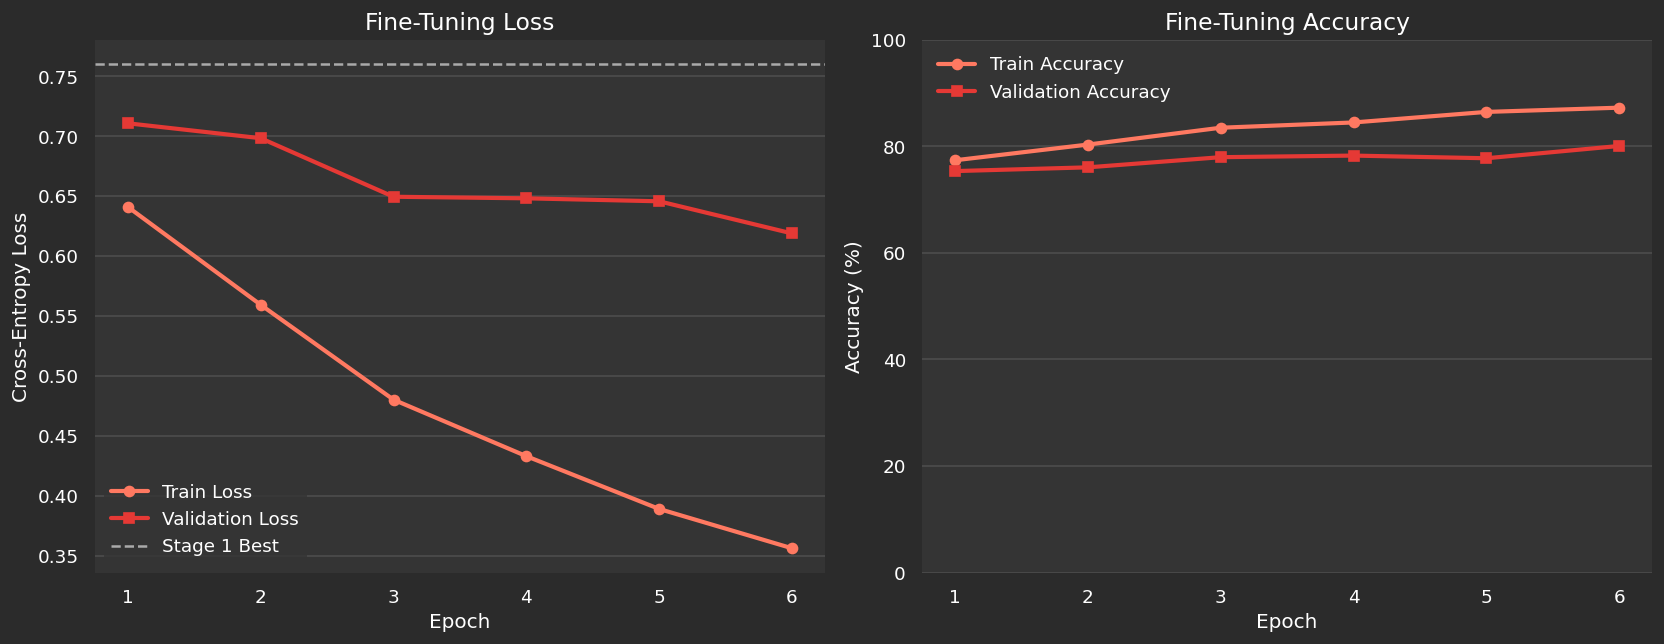

In [ ]:

ft_epochs = np.arange(
    1,
    len(finetune_history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor("#2b2b2b")

for ax in axes:
    ax.set_facecolor("#343434")
    ax.tick_params(colors="white")
    ax.grid(axis="y", alpha=0.12, color="white")
    ax.grid(axis="x", visible=False)

    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(
    ft_epochs,
    finetune_history["train_loss"],
    color="#ff7961",
    marker="o",
    linewidth=2.5,
    label="Train Loss"
)

axes[0].plot(
    ft_epochs,
    finetune_history["val_loss"],
    color="#e53935",
    marker="s",
    linewidth=2.5,
    label="Validation Loss"
)

axes[0].axhline(
    stage1_val_loss,
    color="#aaaaaa",
    linestyle="--",
    linewidth=1.5,
    label="Stage 1 Best"
)

axes[0].set_title("Fine-Tuning Loss", color="white")
axes[0].set_xlabel("Epoch", color="white")
axes[0].set_ylabel("Cross-Entropy Loss", color="white")

axes[1].plot(
    ft_epochs,
    np.array(finetune_history["train_accuracy"]) * 100,
    color="#ff7961",
    marker="o",
    linewidth=2.5,
    label="Train Accuracy"
)

axes[1].plot(
    ft_epochs,
    np.array(finetune_history["val_accuracy"]) * 100,
    color="#e53935",
    marker="s",
    linewidth=2.5,
    label="Validation Accuracy"
)

axes[1].set_title("Fine-Tuning Accuracy", color="white")
axes[1].set_xlabel("Epoch", color="white")
axes[1].set_ylabel("Accuracy (%)", color="white")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xticks(ft_epochs)
    legend = ax.legend(
        facecolor="#343434",
        edgecolor="none"
    )
    for label in legend.get_texts():
        label.set_color("white")

plt.tight_layout()
plt.show()



### 6.3. Анализ результатов Fine-Tuning

На втором этапе обучения выполнена частичная разморозка параметров ResNet18 с последующей оптимизацией последнего остаточного блока `layer4` и классификатора `fc`.

Обучение проводилось в течение 6 эпох с использованием оптимизатора Adam и пониженных скоростей обучения.

В результате Fine-Tuning получены следующие показатели:

| Показатель | До Fine-Tuning | После Fine-Tuning |
|---|---:|---:|
| Train Accuracy | 76.28% | 87.23% |
| Validation Accuracy | 73.02% | 80.04% |
| Validation Loss | 0.7603 | 0.6188 |

Дополнительное обучение позволило увеличить валидационную точность на 7.02 процентного пункта.

Валидационная функция потерь уменьшилась приблизительно на 18.6%, что свидетельствует об улучшении качества модели на валидационной выборке.

Анализ графиков показал устойчивое уменьшение обучающей функции потерь. Валидационная ошибка также имела общую тенденцию к снижению.

На шестой эпохе достигнуто минимальное значение Validation Loss, равное 0.6188. Соответствующие параметры модели сохранены в файле `mushrooms_resnet18_final.pth`.

### Промежуточный вывод

Частичное дообучение свёрточных слоёв ResNet18 повысило качество классификации изображений грибов по сравнению с обучением только последнего полносвязного слоя.

Полученные результаты подтверждают эффективность применения Fine-Tuning в рамках проведённого эксперимента.

Для окончательной оценки обобщающей способности модели необходимо провести тестирование на независимой тестовой выборке.



## 7. Оценка качества классификации

### 7.1. Тестирование модели

После завершения Fine-Tuning выполнена оценка итоговой модели ResNet18 на независимой тестовой выборке.

Для проверки качества используются обучающая, валидационная и тестовая выборки.

Все оценки проводятся в режиме `model.eval()`, при котором отключается обучение модели и применяются детерминированные преобразования изображений.

Основными показателями являются Accuracy и Cross-Entropy Loss.

Тестовая выборка не использовалась для обновления параметров модели или выбора гиперпараметров.


In [ ]:

train_eval_dataset = MushroomSubset(
    mushroom_dataset,
    train_indices,
    eval_transform
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

model.eval()

train_loss, train_acc = run_epoch(
    model, train_eval_loader
)

val_loss, val_acc = run_epoch(
    model, val_loader
)

test_loss, test_acc = run_epoch(
    model, test_loader
)

results_df = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Images": [
        len(train_dataset),
        len(val_dataset),
        len(test_dataset)
    ],
    "Loss": [train_loss, val_loss, test_loss],
    "Accuracy (%)": [
        train_acc * 100,
        val_acc * 100,
        test_acc * 100
    ]
})

display(
    results_df.style.format({
        "Loss": "{:.4f}",
        "Accuracy (%)": "{:.2f}"
    })
)

print(f"\nFinal Test Accuracy: {test_acc:.2%}")


,Dataset,Images,Loss,Accuracy (%)
0,Train,4650,0.3576,87.46
1,Validation,997,0.6188,80.04
2,Test,997,0.6756,78.94



Final Test Accuracy: 78.94%


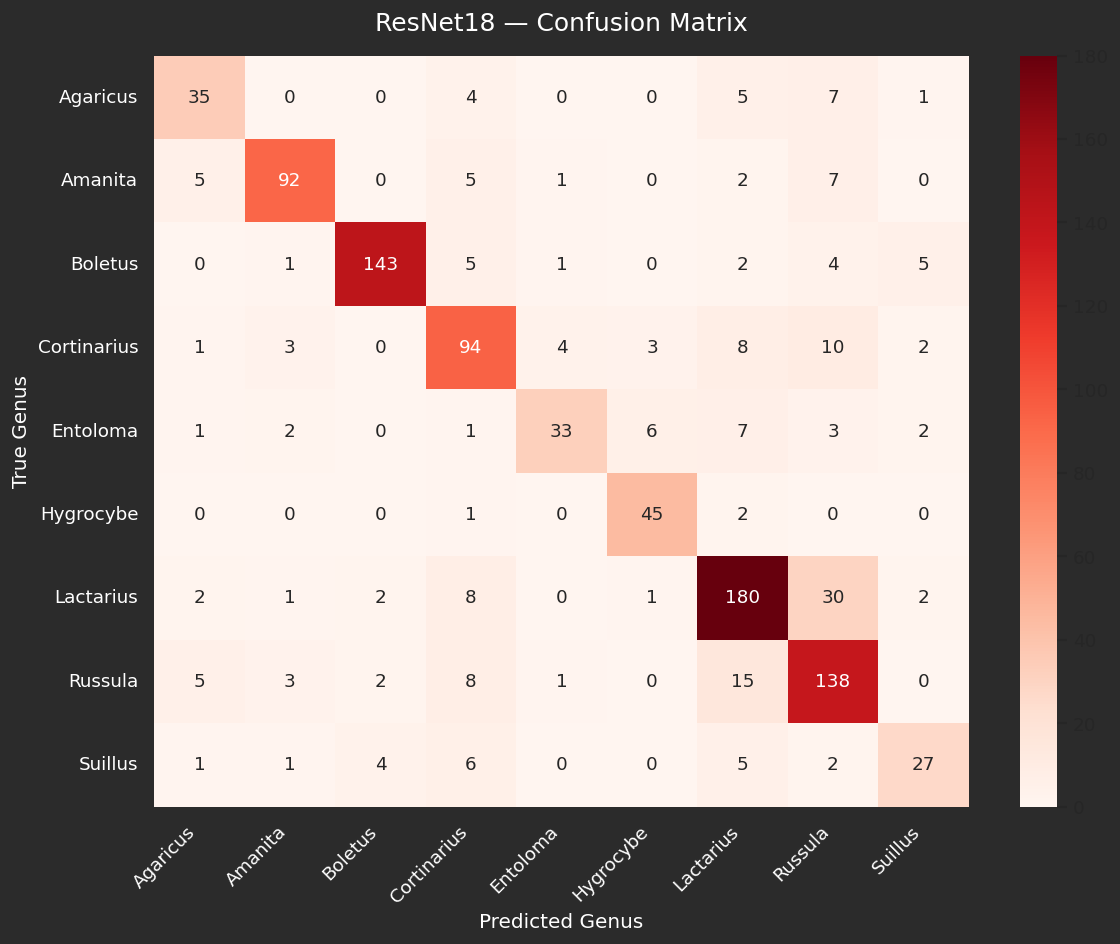

Classification Report:

              precision    recall  f1-score   support

    Agaricus     0.7000    0.6731    0.6863        52
     Amanita     0.8932    0.8214    0.8558       112
     Boletus     0.9470    0.8882    0.9167       161
 Cortinarius     0.7121    0.7520    0.7315       125
    Entoloma     0.8250    0.6000    0.6947        55
   Hygrocybe     0.8182    0.9375    0.8738        48
   Lactarius     0.7965    0.7965    0.7965       226
     Russula     0.6866    0.8023    0.7399       172
     Suillus     0.6923    0.5870    0.6353        46

    accuracy                         0.7894       997
   macro avg     0.7857    0.7620    0.7701       997
weighted avg     0.7949    0.7894    0.7896       997



In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_true = []
y_pred = []

model.eval()

with torch.inference_mode():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(
            predictions.cpu().numpy().tolist()
        )

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(10, 8))

fig.patch.set_facecolor("#2b2b2b")
ax.set_facecolor("#343434")

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0,
    ax=ax
)

ax.set_title(
    "ResNet18 — Confusion Matrix",
    color="white",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Predicted Genus", color="white")
ax.set_ylabel("True Genus", color="white")

ax.tick_params(axis="both", colors="white")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)



### 7.2. Анализ результатов тестирования

После завершения Fine-Tuning проведена оценка итоговой модели ResNet18 на независимой тестовой выборке, содержащей 997 изображений девяти родов грибов.

Получены следующие результаты:

| Показатель | Train | Validation | Test |
|---|---:|---:|---:|
| Accuracy, % | 87.46 | 80.04 | 78.94 |
| Cross-Entropy Loss | 0.3576 | 0.6188 | 0.6756 |

На тестовой выборке правильно классифицированы 787 из 997 изображений, что соответствует точности 78.94%.

Разница между обучающей и тестовой точностью составила 8.52 процентного пункта.

Валидационная и тестовая точности отличаются на 1.10 процентного пункта.

### 7.3. Анализ матрицы ошибок

Для исследования качества классификации отдельных родов грибов построена матрица ошибок.

Наибольшие значения Recall получены для следующих классов:

- Hygrocybe — 93.75%;
- Boletus — 88.82%;
- Amanita — 82.14%.

Наиболее сложными для распознавания оказались:

- Suillus — 58.70%;
- Entoloma — 60.00%;
- Agaricus — 67.31%.

В ходе анализа установлено, что наиболее выраженная путаница наблюдается между классами Lactarius и Russula.

Так, 30 изображений рода Lactarius были отнесены к Russula, а 15 изображений Russula — к Lactarius.

### 7.4. Дополнительные метрики классификации

Для оценки качества с учётом дисбаланса классов рассчитаны Precision, Recall и F1-score.

Получены следующие усреднённые показатели:

| Метрика | Значение |
|---|---:|
| Macro Precision | 0.7857 |
| Macro Recall | 0.7620 |
| Macro F1-score | 0.7701 |
| Weighted F1-score | 0.7896 |

Значение Macro F1-score, равное 0.7701, показывает, что качество распознавания различается между классами.

### Промежуточный вывод

Разработанная модель ResNet18 продемонстрировала способность классифицировать изображения девяти родов грибов с тестовой точностью 78.94%.

Дополнительное обучение последнего свёрточного блока улучшило качество модели относительно первого этапа Transfer Learning по валидационным показателям.

При этом наблюдается снижение точности на независимых тестовых изображениях относительно обучающей выборки.

Полученные результаты подтверждают применимость Transfer Learning к задаче классификации грибов и указывают на необходимость учитывать дисбаланс классов и особенности визуального сходства объектов.



## 8. Визуализация результатов классификации

Для качественного анализа работы ResNet18 выполнена визуализация предсказаний на изображениях независимой тестовой выборки.

Представлены примеры правильной и ошибочной классификации.

Для каждого изображения указываются истинный род гриба и предсказанный моделью класс.

Правильные предсказания выделены зелёным цветом, ошибочные — красным.

Данная визуализация дополняет количественный анализ и позволяет исследовать характерные ошибки классификатора.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

y_true_arr = np.array(y_true)
y_pred_arr = np.array(y_pred)

correct_indices = np.where(
    y_true_arr == y_pred_arr
)[0]

incorrect_indices = np.where(
    y_true_arr != y_pred_arr
)[0]

rng = np.random.default_rng(SEED)

selected_correct = rng.choice(
    correct_indices,
    size=min(6, len(correct_indices)),
    replace=False
)

selected_incorrect = rng.choice(
    incorrect_indices,
    size=min(6, len(incorrect_indices)),
    replace=False
)

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

fig, axes = plt.subplots(
    3, 4, figsize=(15, 12)
)

fig.patch.set_facecolor("#2b2b2b")

for ax, idx in zip(axes.flat, selected_indices):

    original_idx = int(test_dataset.indices[idx])

    path, label = mushroom_dataset.samples[
        original_idx
    ]

    with Image.open(path) as img:
        image = img.convert("RGB").copy()

    predicted = int(y_pred_arr[idx])
    actual = int(y_true_arr[idx])

    correct = predicted == actual

    color = "#66bb6a" if correct else "#ef5350"

    ax.imshow(image)
    ax.set_title(
        f"True: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}",
        fontsize=11,
        color=color,
        pad=10
    )

    ax.axis("off")

for ax in axes.flat[len(selected_indices):]:
    ax.axis("off")

plt.suptitle(
    "ResNet18 — Mushroom Classification Results",
    fontsize=18,
    color="white",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


Output hidden; open in https://colab.research.google.com to view.


### 8.1. Анализ визуальных результатов классификации

Для качественной оценки работы нейронной сети ResNet18 проведена визуализация 12 изображений независимой тестовой выборки.

Представлены шесть правильно классифицированных изображений и шесть изображений, при распознавании которых модель допустила ошибки.

Для каждого объекта указаны истинный и предсказанный роды грибов.

Анализ показал, что модель способна выделять характерные визуальные признаки различных родов. Вместе с тем наблюдаются ошибки при классификации объектов со сходными морфологическими характеристиками.

В частности, выявлены случаи ошибочного отнесения:

- Suillus к Cortinarius;
- Agaricus к Russula;
- Russula к Lactarius.

Ошибки могут быть связаны с визуальным сходством отдельных объектов, различиями в ракурсах съёмки, неоднородным фоном и ограниченной представленностью некоторых классов.

Поскольку правильные и ошибочные предсказания выбраны специально, представленная визуализация не используется для расчёта общей точности классификации.

**Вывод:** визуальный анализ подтверждает работоспособность разработанной модели и позволяет выявить характерные ошибки распознавания. Количественная оценка качества выполняется по полной тестовой выборке.



## 9. Общие выводы

В ходе лабораторной работы разработана и обучена нейросетевая модель для классификации фотографий грибов девяти родов с использованием архитектуры ResNet18 и метода Transfer Learning.

### Основные результаты

1. Исследован набор данных Mushrooms Classification. В исходных каталогах обнаружено 13 428 файлов, представляющих две идентичные копии набора из 6714 изображений.

2. Проведена проверка дублирования и целостности данных. После исключения 69 избыточных копий и одного повреждённого изображения сформирована выборка из 6644 объектов.

3. Данные разделены на обучающую (4650 изображений), валидационную (997) и тестовую (997) выборки.

4. Реализована модель ResNet18 с предварительно обученными весами ImageNet. Исходный классификатор заменён полносвязным слоем с девятью выходами.

5. На первом этапе Transfer Learning выполнялась оптимизация только классификационного слоя. После 12 эпох обучения получена валидационная точность 73.02%.

6. На втором этапе проведён Fine-Tuning последнего остаточного блока `layer4` и классификационного слоя. В результате валидационная точность увеличилась до 80.04%.

7. Проведено окончательное тестирование модели на независимой выборке.

### Итоговые показатели

| Показатель | Значение |
|---|---:|
| Train Accuracy | 87.46% |
| Validation Accuracy | 80.04% |
| Test Accuracy | 78.94% |
| Test Loss | 0.6756 |
| Macro Precision | 0.7857 |
| Macro Recall | 0.7620 |
| Macro F1-score | 0.7701 |
| Weighted F1-score | 0.7896 |

Проведённый Fine-Tuning позволил повысить валидационную точность относительно первого этапа на 7.02 процентного пункта.

Анализ матрицы ошибок показал, что наиболее высокая полнота распознавания достигнута для родов Hygrocybe и Boletus. Наибольшие затруднения наблюдались для Suillus и Entoloma.

Различия между обучающей и тестовой точностью указывают на ограниченную обобщающую способность модели. Качество классификации также зависит от дисбаланса классов и разнообразия исходных изображений.

### Заключение

В результате лабораторной работы продемонстрирована применимость метода Transfer Learning для многоклассовой классификации изображений грибов.

Разработанная модель ResNet18 достигла тестовой точности 78.94% на независимой выборке.

Полученные результаты показывают, что частичное дообучение предварительно обученной свёрточной сети позволяет повысить качество классификации на специализированном наборе изображений.

Для дальнейшего улучшения модели целесообразно исследовать методы балансировки классов, дополнительные аугментации данных и альтернативные нейросетевые архитектуры.


In [ ]:

from google.colab import files
from pathlib import Path

model_path = Path(
    "/content/mushrooms_resnet18_final.pth"
)

assert model_path.exists(), "Файл модели не найден"

print("Model:", model_path.name)
print(
    "Size:",
    round(model_path.stat().st_size / 1024**2, 2),
    "MB"
)

files.download(str(model_path))


Model: mushrooms_resnet18_final.pth
Size: 42.73 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>